# 🎬 IMDb Sentiment Analysis with Transformers

### End-to-End NLP Sentiment Classification Project

This project develops a complete **Natural Language Processing (NLP)** pipeline for classifying movie reviews as **positive or negative** using the IMDb Movie Reviews dataset.

The project begins with systematic data exploration and text analysis, followed by preprocessing and tokenization for Transformer-based models. A pretrained Transformer will then be fine-tuned for sentiment classification and evaluated using multiple performance metrics and detailed error analysis.

The final trained model will be integrated into an interactive **Web Application** for real-time sentiment prediction.

---

### Project Pipeline

**Data Exploration → Text Analysis → Preprocessing → Tokenization → Transformer Fine-Tuning → Model Evaluation → Error Analysis → Inference → Web Application**

---

### Notebook 01 — Data Exploration & Understanding

The objective of this notebook is to understand the **structure, quality, distribution, and linguistic characteristics** of the IMDb dataset before making any preprocessing or modeling decisions.

## 1. Environment Setup & Imports

In [1]:
# Core libraries for data loading and analysis
from datasets import load_dataset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

c:\Python-Envs\nlp-sentiment-2026\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Dataset Loading

In [2]:
# Define the project root directory


project_path = Path.cwd().parent

print(project_path)

g:\My Drive\My-Project\NLP-Sentiment-Analysis-2026


In [3]:
# Hugging Face cache directory
cache_dir = project_path / "hf_cache"

print(cache_dir)

g:\My Drive\My-Project\NLP-Sentiment-Analysis-2026\hf_cache


In [4]:
# Load the IMDb dataset
dataset = load_dataset(
    "stanfordnlp/imdb",
    cache_dir=str(cache_dir)
)

## 3. Dataset Structure

In [5]:
# Display the overall structure of the IMDb dataset
dataset

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    unsupervised: Dataset({
        features: ['text', 'label'],
        num_rows: 50000
    })
})

In [6]:
# Display the first review from the training dataset
dataset["train"][0]

{'text': 'I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefore being a fan of films considered "controversial" I really had to see this for myself.<br /><br />The plot is centered around a young Swedish drama student named Lena who wants to learn everything she can about life. In particular she wants to focus her attentions to making some sort of documentary on what the average Swede thought about certain political issues such as the Vietnam War and race issues in the United States. In between asking politicians and ordinary denizens of Stockholm about their opinions on politics, she has sex with her drama teacher, classmates, and married men.<br /><br />What kills me about I AM CURIOUS-YELLOW is that 40 years ago, this was considered pornographic. Really, the sex and nudity scenes are few and far be

In [7]:
# Display the label names defined in the dataset
dataset["train"].features["label"].names

['neg', 'pos']

In [8]:
# Count the number of samples for each sentiment label
pd.Series(dataset["train"]["label"]).value_counts()

0    12500
1    12500
Name: count, dtype: int64

In [9]:
# Count the number of samples for each sentiment label in the test set
pd.Series(dataset["test"]["label"]).value_counts()

0    12500
1    12500
Name: count, dtype: int64

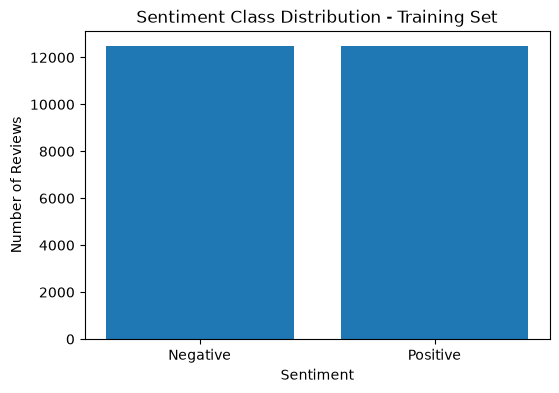

In [12]:
# Calculate the class distribution in the training dataset
class_counts = pd.Series(dataset["train"]["label"]).value_counts().sort_index()

# Create a bar chart for the sentiment class distribution
plt.figure(figsize=(6, 4))
plt.bar(["Negative", "Positive"], class_counts.values)

# Add chart title and axis labels
plt.title("Sentiment Class Distribution - Training Set")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")

# Display the chart
plt.show()

## 4. Review Length Analysis

In [13]:
# Calculate the number of words in each training review
train_review_lengths = [
    len(review.split())
    for review in dataset["train"]["text"]
]

In [15]:
# Display the word counts of the first five training reviews
train_review_lengths[:5]

[288, 214, 93, 118, 311]

In [16]:
# Calculate basic statistics for training review lengths
print("Mean:", np.mean(train_review_lengths))
print("Median:", np.median(train_review_lengths))
print("Minimum:", np.min(train_review_lengths))
print("Maximum:", np.max(train_review_lengths))

Mean: 233.7872
Median: 174.0
Minimum: 10
Maximum: 2470


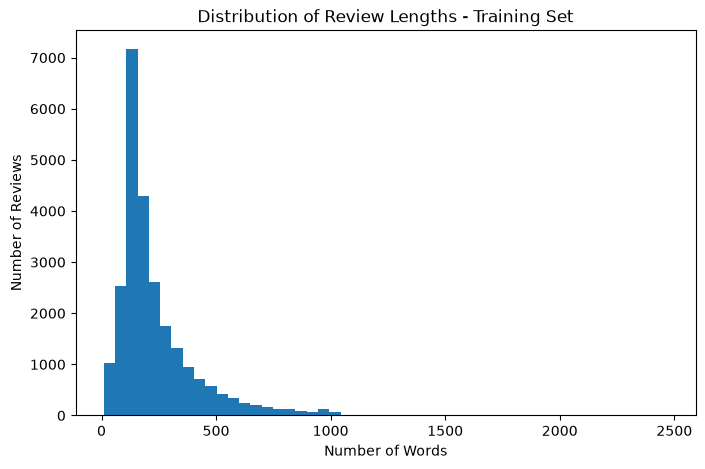

In [17]:
# Visualize the distribution of training review lengths
plt.figure(figsize=(8, 5))
plt.hist(train_review_lengths, bins=50)

# Add chart title and axis labels
plt.title("Distribution of Review Lengths - Training Set")
plt.xlabel("Number of Words")
plt.ylabel("Number of Reviews")

# Display the chart
plt.show()

### Key Finding

The review length distribution is **right-skewed**, meaning that most reviews are relatively short, while a small number are very long. The median review length is **174 words**, compared with a mean of **234 words**, indicating that long reviews increase the average. Therefore, the maximum review length should not be used directly to determine the model input length; percentile and token-length analysis will be considered later.

In [18]:
# Calculate key percentiles of training review lengths
percentiles = np.percentile(
    train_review_lengths,
    [80, 90, 95, 99]
)

# Display the calculated percentiles
print("80th percentile:", percentiles[0])
print("90th percentile:", percentiles[1])
print("95th percentile:", percentiles[2])
print("99th percentile:", percentiles[3])

80th percentile: 325.0
90th percentile: 458.0
95th percentile: 598.0
99th percentile: 913.0


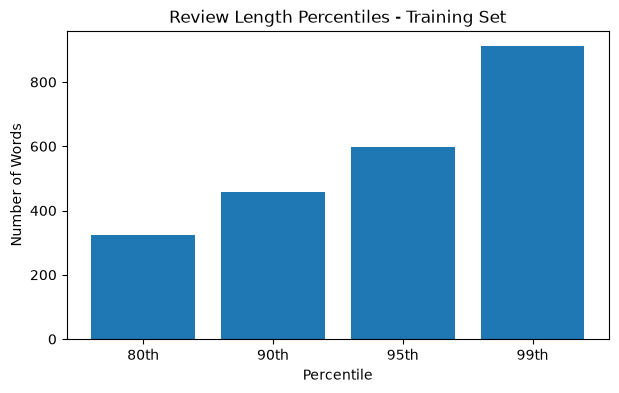

In [19]:
# Visualize review length percentiles
percentile_labels = ["80th", "90th", "95th", "99th"]
percentile_values = [325, 458, 598, 913]

plt.figure(figsize=(7, 4))
plt.bar(percentile_labels, percentile_values)

# Add chart title and axis labels
plt.title("Review Length Percentiles - Training Set")
plt.xlabel("Percentile")
plt.ylabel("Number of Words")

# Display the chart
plt.show()

### Key Finding

Most reviews are substantially shorter than the maximum length of 2,470 words. **95% of reviews contain 598 words or fewer**, while **99% contain 913 words or fewer**, confirming that very long reviews represent only a small portion of the dataset.

In [20]:
# Separate review lengths by sentiment
negative_lengths = [
    length
    for length, label in zip(train_review_lengths, dataset["train"]["label"])
    if label == 0
]

positive_lengths = [
    length
    for length, label in zip(train_review_lengths, dataset["train"]["label"])
    if label == 1
]

In [21]:
# Compare basic review length statistics by sentiment
print("Negative - Mean:", np.mean(negative_lengths))
print("Negative - Median:", np.median(negative_lengths))

print("Positive - Mean:", np.mean(positive_lengths))
print("Positive - Median:", np.median(positive_lengths))

Negative - Mean: 230.86784
Negative - Median: 174.0
Positive - Mean: 236.70656
Positive - Median: 174.0


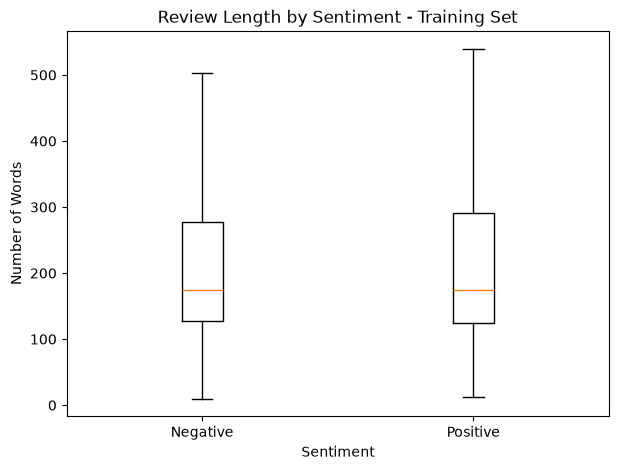

In [22]:
# Compare review length distributions between negative and positive reviews
plt.figure(figsize=(7, 5))

plt.boxplot(
    [negative_lengths, positive_lengths],
    tick_labels=["Negative", "Positive"],
    showfliers=False
)

# Add chart title and axis labels
plt.title("Review Length by Sentiment - Training Set")
plt.xlabel("Sentiment")
plt.ylabel("Number of Words")

# Display the chart
plt.show()

### Key Finding

Positive and negative reviews have very similar length distributions. Both classes have a median length of **174 words**, with only a small difference in their mean lengths. This suggests that **review length alone is unlikely to be a strong indicator of sentiment**.

## 5. Text Quality Analysis

In [23]:
# Count training reviews containing HTML line break tags
html_review_count = sum(
    "<br />" in review
    for review in dataset["train"]["text"]
)

# Calculate the percentage of affected reviews
html_review_percentage = (
    html_review_count / len(dataset["train"]) * 100
)

print("Reviews containing <br />:", html_review_count)
print("Percentage:", round(html_review_percentage, 2), "%")

Reviews containing <br />: 14665
Percentage: 58.66 %


In [24]:
# Check for missing or empty reviews in the training dataset
missing_reviews = sum(
    review is None
    for review in dataset["train"]["text"]
)

empty_reviews = sum(
    not review.strip()
    for review in dataset["train"]["text"]
    if review is not None
)

print("Missing reviews:", missing_reviews)
print("Empty reviews:", empty_reviews)

Missing reviews: 0
Empty reviews: 0


### Key Finding

The training dataset contains **no missing or empty reviews**, indicating complete text coverage across all 25,000 samples.

In [25]:
# Count duplicated reviews in the training dataset
train_texts = pd.Series(dataset["train"]["text"])

duplicate_count = train_texts.duplicated().sum()

# Calculate the percentage of duplicated reviews
duplicate_percentage = (
    duplicate_count / len(train_texts) * 100
)

print("Duplicate reviews:", duplicate_count)
print("Percentage:", round(duplicate_percentage, 2), "%")

Duplicate reviews: 96
Percentage: 0.38 %


In [26]:
# Create a DataFrame containing review texts and labels
train_df = pd.DataFrame({
    "text": dataset["train"]["text"],
    "label": dataset["train"]["label"]
})

# Find texts associated with more than one sentiment label
label_conflicts = (
    train_df.groupby("text")["label"]
    .nunique()
)

label_conflicts = label_conflicts[label_conflicts > 1]

print("Reviews with conflicting labels:", len(label_conflicts))

Reviews with conflicting labels: 0


### Key Finding

Only **96 duplicate reviews (0.38%)** were found in the training set, and no duplicated texts have conflicting sentiment labels. Overall, duplicate-related data quality issues are minimal.

## 6. Sentiment Examples


In [27]:
# Display sample negative and positive reviews
negative_samples = train_df[train_df["label"] == 0]["text"].head(3)
positive_samples = train_df[train_df["label"] == 1]["text"].head(3)

print("NEGATIVE REVIEWS\n")

for i, review in enumerate(negative_samples, 1):
    print(f"Negative Review {i}:")
    print(review[:500])
    print("\n" + "-" * 80 + "\n")

print("\nPOSITIVE REVIEWS\n")

for i, review in enumerate(positive_samples, 1):
    print(f"Positive Review {i}:")
    print(review[:500])
    print("\n" + "-" * 80 + "\n")

NEGATIVE REVIEWS

Negative Review 1:
I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefore being a fan of films considered "controversial" I really had to see this for myself.<br /><br />The plot is centered around a young Swedish drama student named Lena who wants to learn everything she can about life. In particular she wants to focus her attent

--------------------------------------------------------------------------------

Negative Review 2:
"I Am Curious: Yellow" is a risible and pretentious steaming pile. It doesn't matter what one's political views are because this film can hardly be taken seriously on any level. As for the claim that frontal male nudity is an automatic NC-17, that isn't true. I've seen R-rated films with male nudity. Granted, they only offer some fleeting views, but where ar

### Key Finding

The reviews contain complex sentiment expressions, including mixed opinions, negation, and contextual language. Positive reviews may contain negative statements and vice versa, suggesting that sentiment classification requires understanding the overall context rather than relying only on individual sentiment words.

## 7. Key Findings


- The IMDb training set contains **25,000 labeled reviews**, evenly balanced between positive and negative sentiment.
- Review lengths are **right-skewed**, with a median of **174 words** and a mean of approximately **234 words**.
- **95%** of reviews contain **598 words or fewer**, while **99%** contain **913 words or fewer**.
- Positive and negative reviews have very similar length distributions.
- **58.66%** of reviews contain `<br />` HTML tags.
- No missing or empty reviews were found.
- Only **96 duplicate reviews (0.38%)** were identified, with no conflicting sentiment labels.
- Reviews often contain mixed opinions, negation, and contextual sentiment, indicating that classification requires more than simple keyword matching.